In [1]:
# ==============================================================================
# MEMBER 1: DATA PREPARATION & TRAIN-TEST SPLIT LEAD
# Task: Source documentation, Initial Inspection, 70/30 Split & Imputation
# ==============================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as snss
from sklearn.model_selection import train_test_split

# ------------------------------------------------------------------------------
# STEP 1: Document Dataset Source URL
# ------------------------------------------------------------------------------
DATASET_URL = "https://docs.google.com/spreadsheets/d/1wQTS2-bZKC2n17To2Smp1NAFMFeBEjh_rklu0wi7mu0/edit#gid=1445603174"

# Write URL to a local reference file as required by project submission rules
with open("dataset_url.txt", "w") as f:
    f.write(f"Original Dataset URL:\n{DATASET_URL}\n")

print("✓ Dataset URL saved to dataset_url.txt")

# ------------------------------------------------------------------------------
# STEP 2: Load Dataset directly from Google Sheets
# ------------------------------------------------------------------------------
# Convert Google Sheets URL to direct CSV export link
SHEET_ID = "1wQTS2-bZKC2n17To2Smp1NAFMFeBEjh_rklu0wi7mu0"
GID = "1445603174"
csv_export_url = f"https://docs.google.com/spreadsheets/d/{SHEET_ID}/export?format=csv&gid={GID}"

# Load dataset into pandas DataFrame
df = pd.read_csv(csv_export_url)

# ------------------------------------------------------------------------------
# STEP 3: Initial Data Inspection
# ------------------------------------------------------------------------------
print("\n" + "="*50)
print("INITIAL DATASET INSPECTION")
print("="*50)

print(f"\n1. Dataset Shape (Rows, Columns): {df.shape}")

print("\n2. First 5 Rows:")
display(df.head())

print("\n3. Data Types & Non-Null Counts:")
print(df.info())

print("\n4. Missing Values per Column:")
missing_counts = df.isnull().sum()
print(missing_counts)

print("\n5. Summary Statistics:")
display(df.describe())

# ------------------------------------------------------------------------------
# STEP 4: 70% Train / 30% Test Split
# ------------------------------------------------------------------------------
# Target column for disease prediction (e.g., 'Stroke')
TARGET_COL = 'Stroke'

# Separate features (X) and target (y)
X = df.drop(columns=[TARGET_COL])
y = df[TARGET_COL]

# Perform 70/30 stratified train/test split (to maintain class balance ratio)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

print("\n" + "="*50)
print("TRAIN / TEST SPLIT SUMMARY")
print("="*50)
print(f"Training Set Shape : {X_train.shape} ({len(X_train)/len(df):.1%} of data)")
print(f"Testing Set Shape  : {X_test.shape} ({len(X_test)/len(df):.1%} of data)")

# Recombine X and y for train and test dataframes
train_df = X_train.copy()
train_df[TARGET_COL] = y_train

test_df = X_test.copy()
test_df[TARGET_COL] = y_test

# ------------------------------------------------------------------------------
# STEP 5: Missing Value Inspection & Imputation Check
# ------------------------------------------------------------------------------
print("\n" + "="*50)
print("MISSING VALUE INSPECTION")
print("="*50)

print("Total missing values in dataset:", train_df.isnull().sum().sum())

# Since this dataset has 0 missing values, we print a confirmation message
# instead of an empty heatmap plot.
if train_df.isnull().sum().sum() == 0:
    print("✓ Dataset is fully complete. No imputation required for this dataset.")
else:
    # Imputation fallback if your specific split introduces any NaNs
    num_cols = train_df.select_dtypes(include=['float64', 'int64']).columns.drop(TARGET_COL, errors='ignore')
    for col in num_cols:
        median_val = train_df[col].median()
        train_df[col].fillna(median_val, inplace=True)
        test_df[col].fillna(median_val, inplace=True)
    print("✓ Missing values successfully imputed using training set medians.")

# ------------------------------------------------------------------------------
# STEP 6: Save Train and Test Datasets
# ------------------------------------------------------------------------------
train_df.to_csv('train_set.csv', index=False)
test_df.to_csv('test_set.csv', index=False)

print("\n✓ 'train_set.csv' and 'test_set.csv' successfully exported for Members 2, 3, and 4.")

✓ Dataset URL saved to dataset_url.txt

INITIAL DATASET INSPECTION

1. Dataset Shape (Rows, Columns): (2000, 15)

2. First 5 Rows:


,Patient_ID,Age,Gender,BMI,Blood_Pressure_Systolic,Blood_Pressure_Diastolic,Cholesterol,Glucose_Level,Smoking,Alcohol_Intake,Physical_Activity,Family_History,Heart_Disease,Diabetes,Stroke
0,1,69,Male,34.1,127,71,184,154,1,1,0,0,0,1,0
1,2,32,Male,25.0,148,69,177,136,1,1,1,0,0,0,0
2,3,78,Male,25.2,98,93,252,110,0,0,0,0,0,0,0
3,4,38,Male,9.6,162,102,274,87,1,0,1,0,0,0,0
4,5,41,Female,29.0,161,69,251,127,0,1,1,0,0,0,0



3. Data Types & Non-Null Counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 15 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Patient_ID                2000 non-null   int64  
 1   Age                       2000 non-null   int64  
 2   Gender                    2000 non-null   object 
 3   BMI                       2000 non-null   float64
 4   Blood_Pressure_Systolic   2000 non-null   int64  
 5   Blood_Pressure_Diastolic  2000 non-null   int64  
 6   Cholesterol               2000 non-null   int64  
 7   Glucose_Level             2000 non-null   int64  
 8   Smoking                   2000 non-null   int64  
 9   Alcohol_Intake            2000 non-null   int64  
 10  Physical_Activity         2000 non-null   int64  
 11  Family_History            2000 non-null   int64  
 12  Heart_Disease             2000 non-null   int64  
 13  Diabetes                  200

,Patient_ID,Age,BMI,Blood_Pressure_Systolic,Blood_Pressure_Diastolic,Cholesterol,Glucose_Level,Smoking,Alcohol_Intake,Physical_Activity,Family_History,Heart_Disease,Diabetes,Stroke
count,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.0000,2000.000000,2000.000000,2000.000000,2000.000000
mean,1000.500000,50.273000,26.977350,134.523500,88.995500,223.980500,132.979500,0.496000,0.503000,0.4950,0.501500,0.080500,0.131000,0.051000
std,577.494589,19.427202,4.945219,26.139856,17.222043,43.212993,37.039574,0.500109,0.500116,0.5001,0.500123,0.272134,0.337485,0.220053
min,1.000000,18.000000,9.600000,90.000000,60.000000,150.000000,70.000000,0.000000,0.000000,0.0000,0.000000,0.000000,0.000000,0.000000
25%,500.750000,33.750000,23.600000,112.000000,74.000000,187.000000,100.000000,0.000000,0.000000,0.0000,0.000000,0.000000,0.000000,0.000000
50%,1000.500000,50.000000,26.900000,134.500000,89.000000,224.000000,133.000000,0.000000,1.000000,0.0000,1.000000,0.000000,0.000000,0.000000
75%,1500.250000,67.000000,30.500000,158.000000,104.000000,261.000000,165.000000,1.000000,1.000000,1.0000,1.000000,0.000000,0.000000,0.000000
max,2000.000000,84.000000,42.300000,179.000000,119.000000,299.000000,199.000000,1.000000,1.000000,1.0000,1.000000,1.000000,1.000000,1.000000



TRAIN / TEST SPLIT SUMMARY
Training Set Shape : (1400, 14) (70.0% of data)
Testing Set Shape  : (600, 14) (30.0% of data)

MISSING VALUE INSPECTION
Total missing values in dataset: 0
✓ Dataset is fully complete. No imputation required for this dataset.

✓ 'train_set.csv' and 'test_set.csv' successfully exported for Members 2, 3, and 4.


In [2]:
# ==============================================================================
# MEMBER 2: EDA LEAD — setup
# ==============================================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 100

# Use Member 1's in-memory training set; fall back to the exported CSV
# if this section is run on its own.
import os
try:
    eda_df = train_df.copy()
except NameError:
    if os.path.exists("train_set.csv"):
        eda_df = pd.read_csv("train_set.csv")
    else:
        # Rebuild the exact same 70/30 split Member 1 uses (same random_state and stratify)
        from sklearn.model_selection import train_test_split
        _url = ("https://docs.google.com/spreadsheets/d/1wQTS2-bZKC2n17To2Smp1NAFMFeBEjh_rklu0wi7mu0"
                "/export?format=csv&gid=1445603174")
        _df = pd.read_csv(_url)
        eda_df, _ = train_test_split(_df, test_size=0.30, random_state=42, stratify=_df["Stroke"])

# Patient_ID is an identifier, not a feature — exclude it from all analysis
eda_df = eda_df.drop(columns=["Patient_ID"], errors="ignore")

TARGETS   = ["Heart_Disease", "Diabetes", "Stroke"]
VITALS    = ["Age", "BMI", "Blood_Pressure_Systolic", "Blood_Pressure_Diastolic",
             "Cholesterol", "Glucose_Level"]
LIFESTYLE = ["Smoking", "Alcohol_Intake", "Physical_Activity", "Family_History"]

print(f"EDA is running on the TRAINING set only: {eda_df.shape[0]} rows, {eda_df.shape[1]} columns")
assert eda_df.shape[0] < 2000, "Looks like the full dataset was loaded — EDA must use the training split only."

EDA is running on the TRAINING set only: 1400 rows, 14 columns


2.1 Descriptive statistics

In [3]:
print("=" * 60)
print("NUMERIC SUMMARY (training set)")
print("=" * 60)
display(eda_df[VITALS].describe().T.round(2))

print("\n" + "=" * 60)
print("CATEGORICAL / BINARY VALUE COUNTS (training set)")
print("=" * 60)
for col in ["Gender"] + LIFESTYLE:
    counts = eda_df[col].value_counts().sort_index()
    pct = (counts / len(eda_df) * 100).round(1)
    print(f"\n{col}:")
    print(pd.DataFrame({"count": counts, "percent": pct}).to_string())

NUMERIC SUMMARY (training set)


,count,mean,std,min,25%,50%,75%,max
Age,1400.0,50.09,19.50,18.0,33.00,50.0,67.00,84.0
BMI,1400.0,26.98,4.92,9.6,23.60,26.8,30.42,42.3
Blood_Pressure_Systolic,1400.0,134.66,26.11,90.0,112.00,135.0,158.00,179.0
Blood_Pressure_Diastolic,1400.0,88.98,17.13,60.0,74.00,89.0,104.00,119.0
Cholesterol,1400.0,224.21,43.57,150.0,186.75,224.5,263.00,299.0
Glucose_Level,1400.0,132.89,36.82,70.0,100.00,133.0,164.00,199.0



CATEGORICAL / BINARY VALUE COUNTS (training set)

Gender:
        count  percent
Gender                
Female    691     49.4
Male      709     50.6

Smoking:
         count  percent
Smoking                
0          698     49.9
1          702     50.1

Alcohol_Intake:
                count  percent
Alcohol_Intake                
0                 695     49.6
1                 705     50.4

Physical_Activity:
                   count  percent
Physical_Activity                
0                    698     49.9
1                    702     50.1

Family_History:
                count  percent
Family_History                
0                 697     49.8
1                 703     50.2


2.2 Target class balance

Rare positive classes mean accuracy is misleading: a model that always predicts "no stroke" would already be about 95% accurate. This is why Member 4 balances the training data and why we evaluate with Precision, Recall and F1.

,positives,negatives,positive_%,imbalance_ratio (neg:pos)
Heart_Disease,109,1291,7.8,11.8
Diabetes,174,1226,12.4,7.0
Stroke,71,1329,5.1,18.7


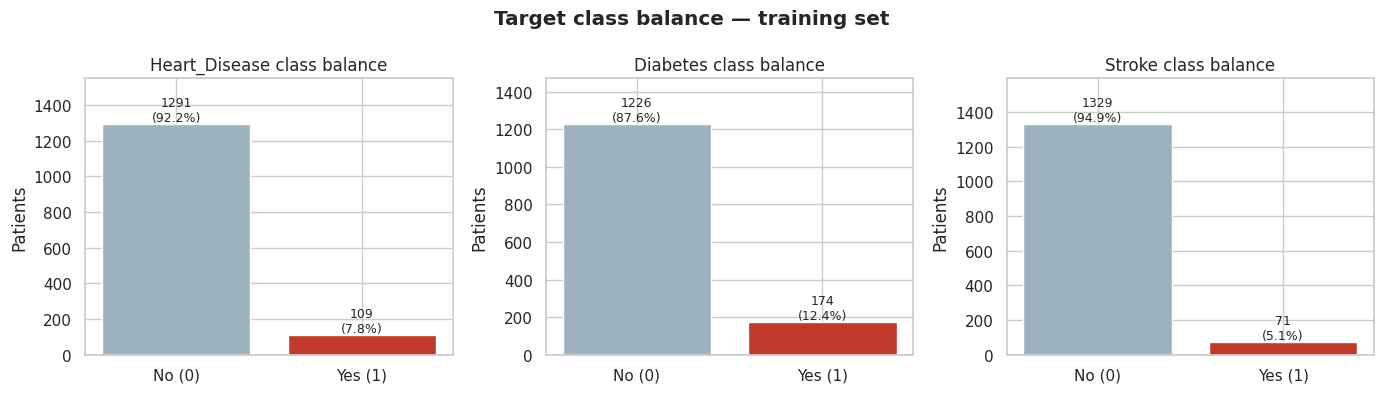

In [4]:
balance = pd.DataFrame({
    "positives": eda_df[TARGETS].sum(),
    "negatives": (eda_df[TARGETS] == 0).sum(),
})
balance["positive_%"] = (balance["positives"] / len(eda_df) * 100).round(1)
balance["imbalance_ratio (neg:pos)"] = (balance["negatives"] / balance["positives"]).round(1)
display(balance)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, t in zip(axes, TARGETS):
    counts = eda_df[t].value_counts().sort_index()
    ax.bar(["No (0)", "Yes (1)"], counts.values, color=["#9db4c0", "#c0392b"])
    for i, v in enumerate(counts.values):
        ax.text(i, v, f"{v}\n({v/len(eda_df):.1%})", ha="center", va="bottom", fontsize=9)
    ax.set_title(f"{t} class balance")
    ax.set_ylabel("Patients")
    ax.set_ylim(0, counts.max() * 1.2)
plt.suptitle("Target class balance — training set", fontweight="bold")
plt.tight_layout()
plt.show()

2.3 Distributions of the numeric vitals

Skewness near 0 means a roughly symmetric distribution; values beyond about ±1 would suggest a log or power transform before scaling.

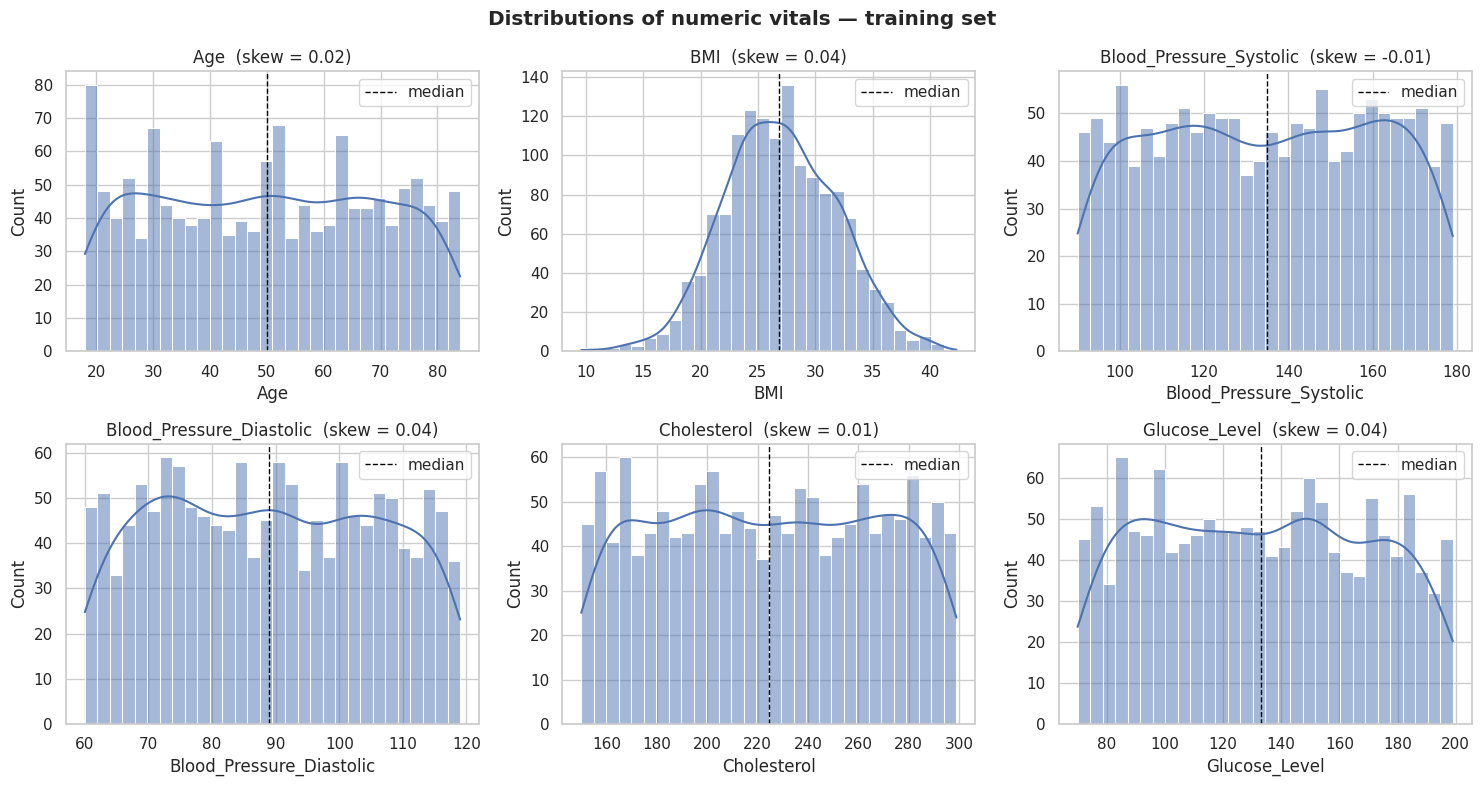

,skewness,needs_transform?
Age,0.018,no
BMI,0.041,no
Blood_Pressure_Systolic,-0.014,no
Blood_Pressure_Diastolic,0.040,no
Cholesterol,0.008,no
Glucose_Level,0.044,no


In [5]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, VITALS):
    sns.histplot(eda_df[col], kde=True, bins=30, ax=ax, color="#4c72b0")
    ax.axvline(eda_df[col].median(), color="black", linestyle="--", linewidth=1, label="median")
    ax.set_title(f"{col}  (skew = {eda_df[col].skew():.2f})")
    ax.legend()
plt.suptitle("Distributions of numeric vitals — training set", fontweight="bold")
plt.tight_layout()
plt.show()

skew_table = eda_df[VITALS].skew().round(3).to_frame("skewness")
skew_table["needs_transform?"] = np.where(skew_table["skewness"].abs() > 1, "YES", "no")
display(skew_table)

2.4 Age vs. Stroke risk

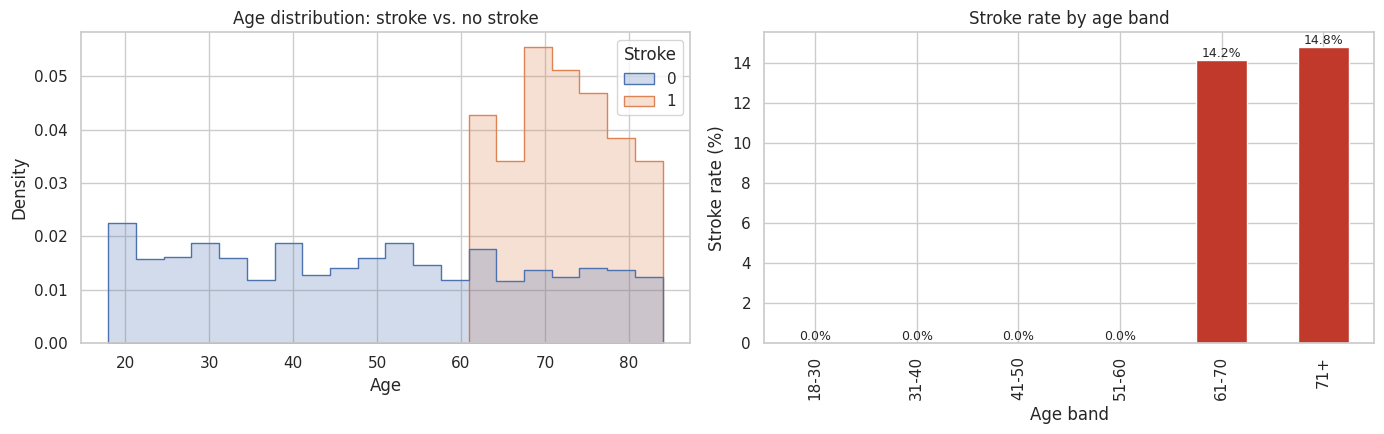

Stroke rate (%) by age band:
Age
18-30     0.0
31-40     0.0
41-50     0.0
51-60     0.0
61-70    14.2
71+      14.8


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

sns.histplot(data=eda_df, x="Age", hue="Stroke", bins=20, stat="density",
             common_norm=False, element="step", ax=axes[0])
axes[0].set_title("Age distribution: stroke vs. no stroke")

age_bands = pd.cut(eda_df["Age"], bins=[17, 30, 40, 50, 60, 70, 90],
                   labels=["18-30", "31-40", "41-50", "51-60", "61-70", "71+"])
stroke_by_age = eda_df.groupby(age_bands, observed=False)["Stroke"].mean() * 100
stroke_by_age.plot(kind="bar", ax=axes[1], color="#c0392b")
axes[1].set_title("Stroke rate by age band")
axes[1].set_ylabel("Stroke rate (%)")
axes[1].set_xlabel("Age band")
for i, v in enumerate(stroke_by_age.values):
    axes[1].text(i, v, f"{v:.1f}%", ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.show()

print("Stroke rate (%) by age band:")
print(stroke_by_age.round(1).to_string())

2.5 Vitals vs. each disease outcome

Box plots compare each vital between patients with and without the condition. A clear shift in the box means that vital separates the classes and is likely to be a useful predictor.

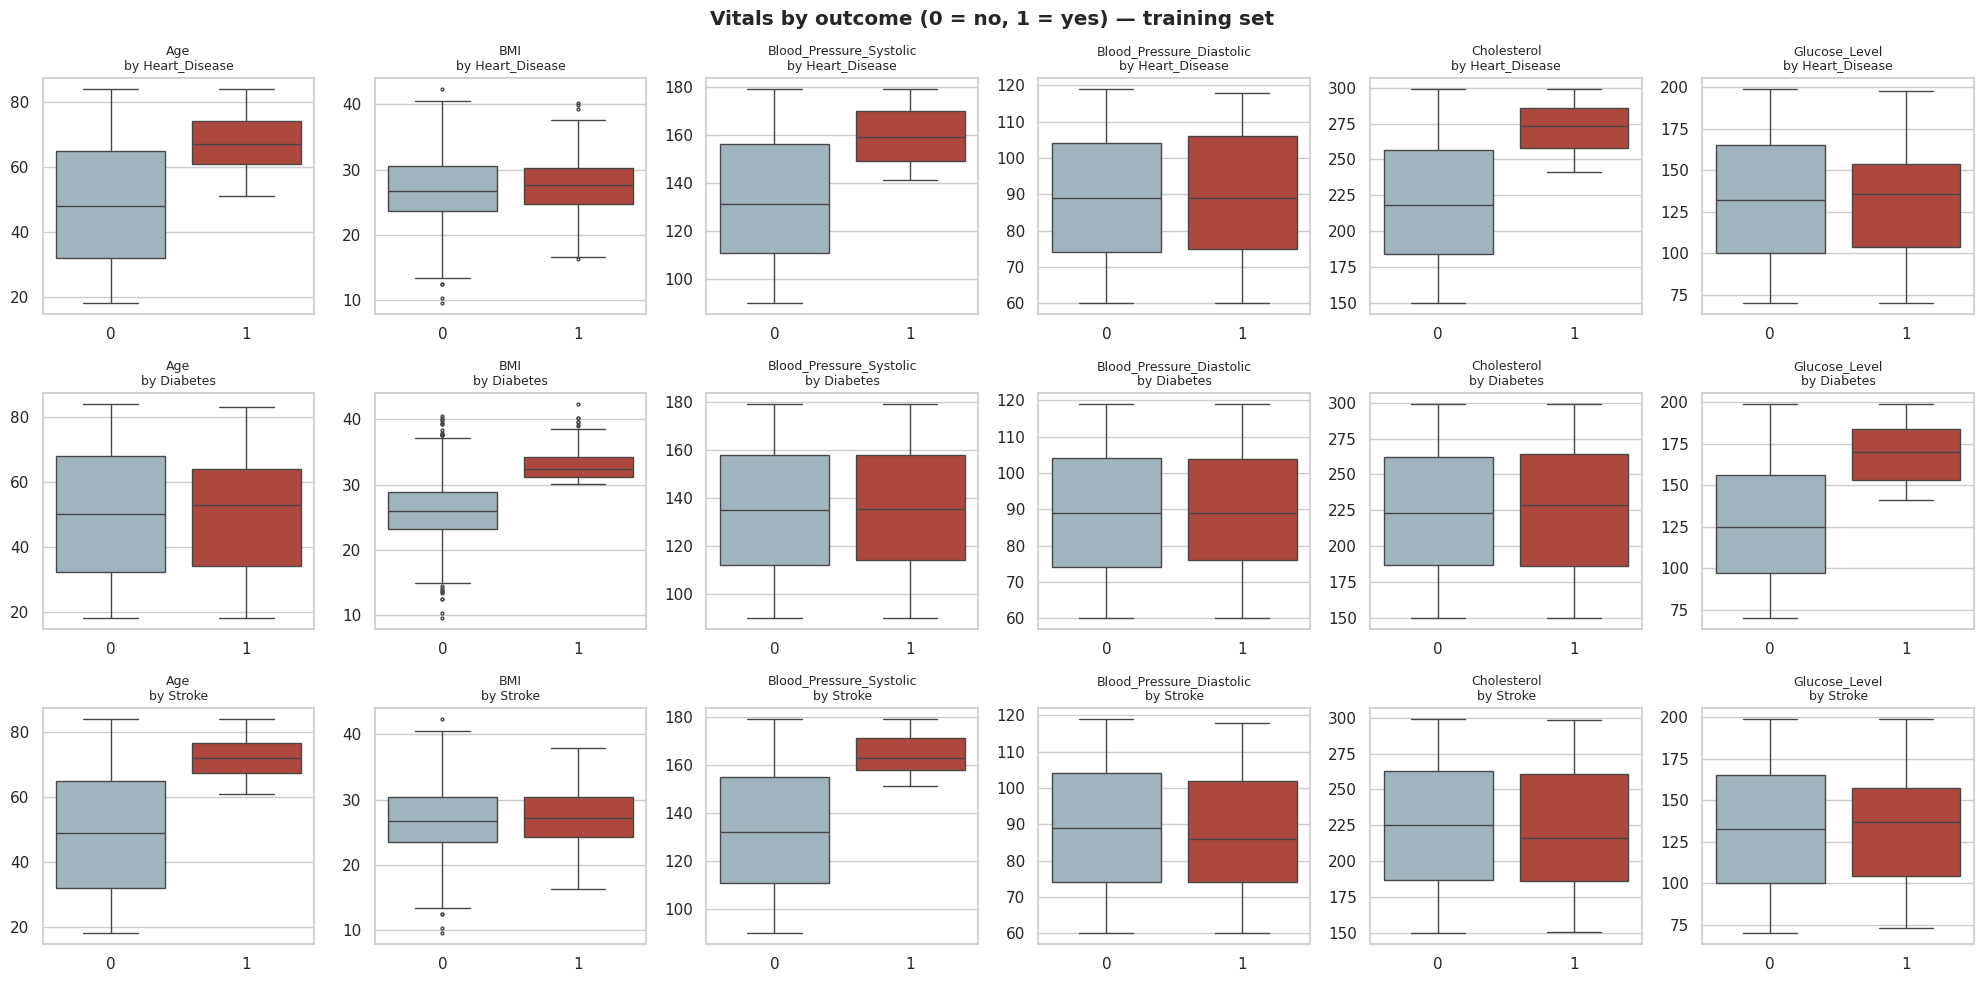

Difference in mean (positive minus negative) for each vital:


,Age,BMI,Blood_Pressure_Systolic,Blood_Pressure_Diastolic,Cholesterol,Glucose_Level
Heart_Disease,18.58,0.67,26.23,0.91,50.94,-0.57
Diabetes,0.26,6.95,0.27,0.30,1.57,41.42
Stroke,23.32,0.37,30.71,-1.72,-2.14,0.17


In [7]:
fig, axes = plt.subplots(len(TARGETS), len(VITALS), figsize=(20, 10))
for r, t in enumerate(TARGETS):
    for c, col in enumerate(VITALS):
        ax = axes[r, c]
        sns.boxplot(data=eda_df, x=t, y=col, ax=ax, hue=t, legend=False,
                    palette={0: "#9db4c0", 1: "#c0392b"}, fliersize=2)
        ax.set_title(f"{col}\nby {t}", fontsize=9)
        ax.set_xlabel("")
        ax.set_ylabel("")
plt.suptitle("Vitals by outcome (0 = no, 1 = yes) — training set", fontweight="bold")
plt.tight_layout()
plt.show()

# Mean of each vital for positive vs. negative patients
diff_rows = []
for t in TARGETS:
    g = eda_df.groupby(t)[VITALS].mean()
    diff_rows.append((g.loc[1] - g.loc[0]).rename(t))
print("Difference in mean (positive minus negative) for each vital:")
display(pd.DataFrame(diff_rows).round(2))

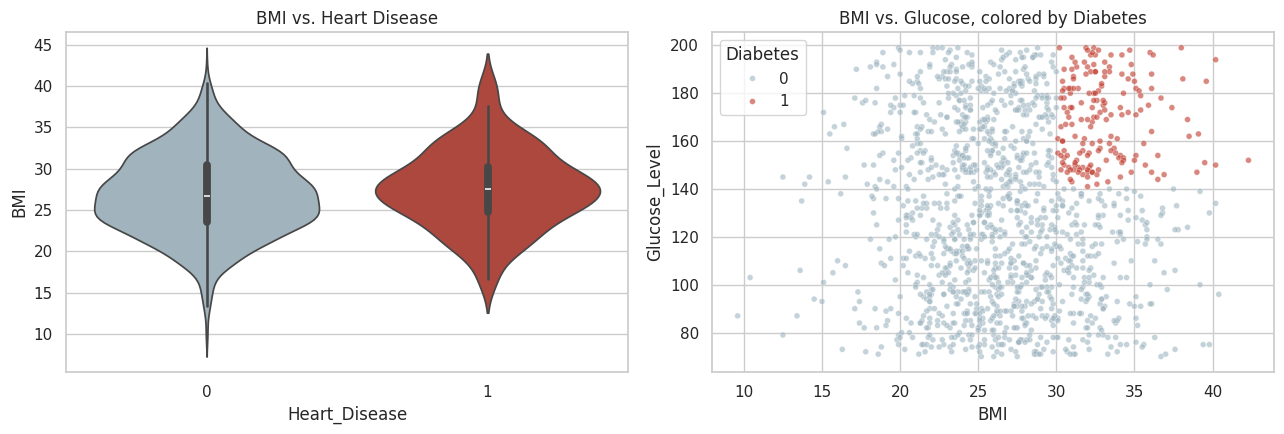

In [8]:
# Highlighted pairs from the project brief
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.violinplot(data=eda_df, x="Heart_Disease", y="BMI", hue="Heart_Disease", legend=False,
               palette={0: "#9db4c0", 1: "#c0392b"}, ax=axes[0])
axes[0].set_title("BMI vs. Heart Disease")
sns.scatterplot(data=eda_df, x="BMI", y="Glucose_Level", hue="Diabetes",
                palette={0: "#9db4c0", 1: "#c0392b"}, alpha=0.6, s=18, ax=axes[1])
axes[1].set_title("BMI vs. Glucose, colored by Diabetes")
plt.tight_layout()
plt.show()

2.6 Lifestyle factors vs. disease rates

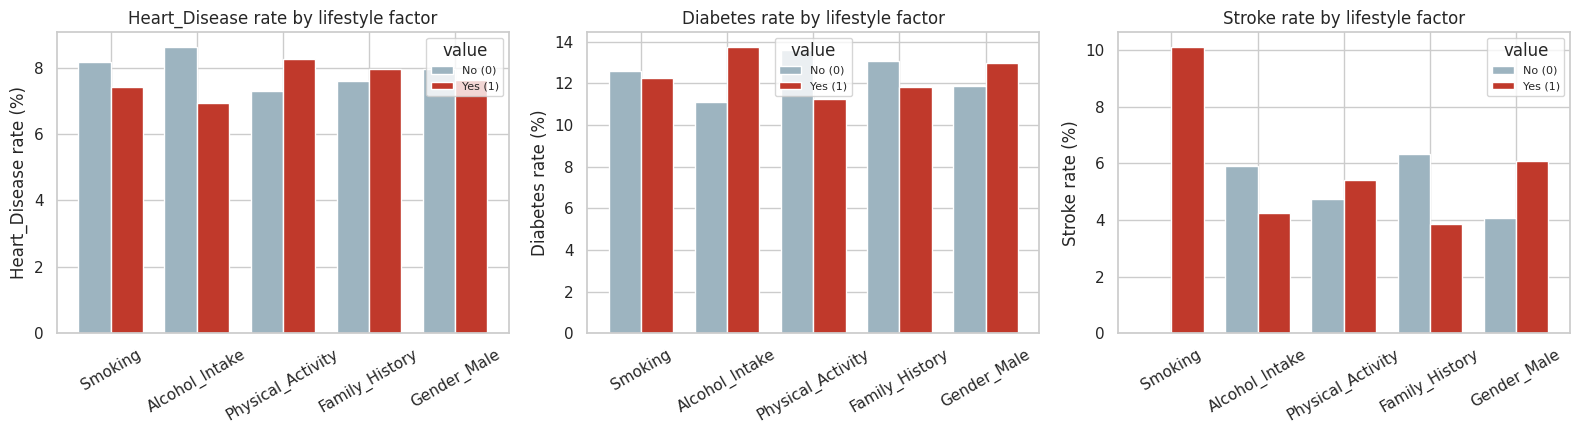

In [9]:
life_df = eda_df.copy()
life_df["Gender_Male"] = (life_df["Gender"] == "Male").astype(int)  # for this plot only
FACTORS = LIFESTYLE + ["Gender_Male"]

fig, axes = plt.subplots(1, len(TARGETS), figsize=(16, 4.5), sharey=False)
for ax, t in zip(axes, TARGETS):
    rates = pd.DataFrame({
        f: life_df.groupby(f)[t].mean() * 100 for f in FACTORS
    }).T
    rates.columns = ["No (0)", "Yes (1)"]
    rates.plot(kind="bar", ax=ax, color=["#9db4c0", "#c0392b"], width=0.75)
    ax.set_title(f"{t} rate by lifestyle factor")
    ax.set_ylabel(f"{t} rate (%)")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=30)
    ax.legend(title="value", fontsize=8)
plt.tight_layout()
plt.show()

2.7 Correlation heatmap

Gender is mapped to 0/1 here only for this plot; the real encoding is done by Member 3. Targets are included so we can see which features move with each outcome.

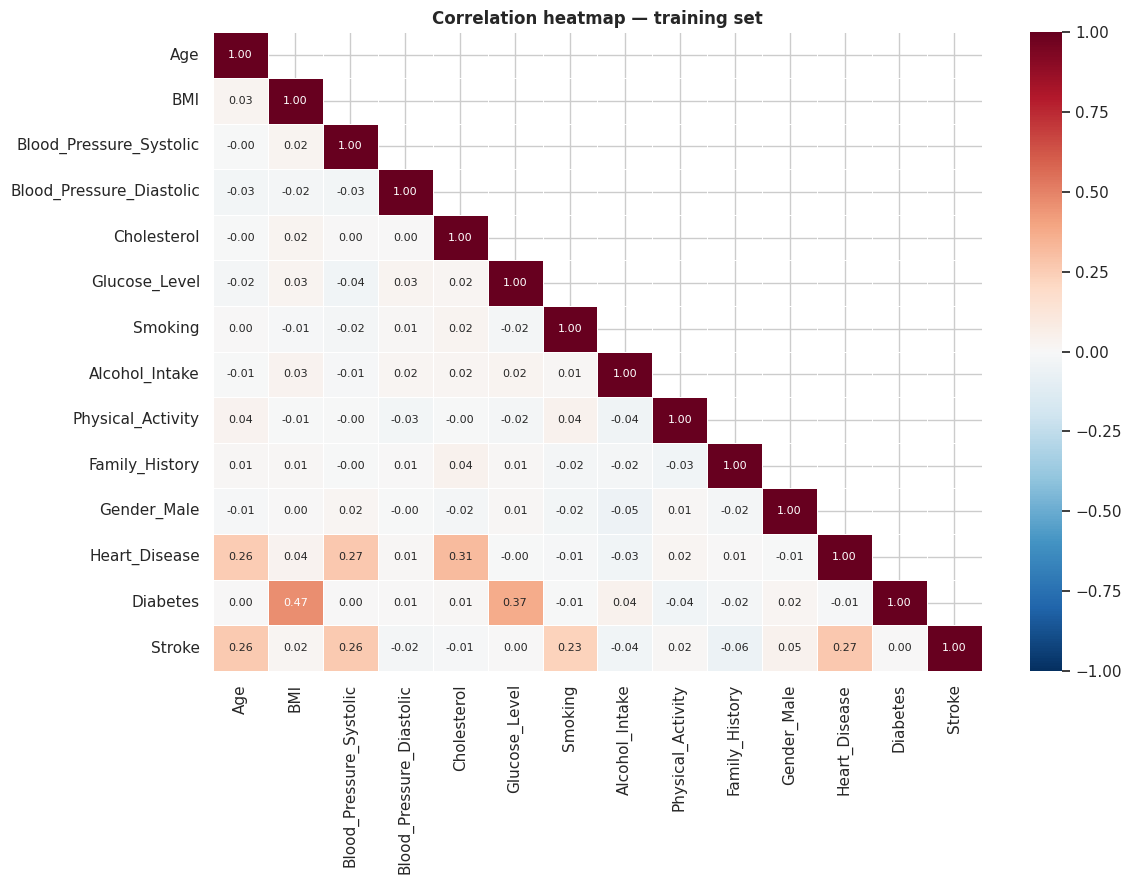

Strongest correlations with each target (absolute value):
  Heart_Disease : Cholesterol (+0.31), Blood_Pressure_Systolic (+0.27), Age (+0.26), BMI (+0.04)
  Diabetes      : BMI (+0.47), Glucose_Level (+0.37), Alcohol_Intake (+0.04), Physical_Activity (-0.04)
  Stroke        : Age (+0.26), Blood_Pressure_Systolic (+0.26), Smoking (+0.23), Family_History (-0.06)

Highest feature-to-feature correlations:
Alcohol_Intake           Gender_Male          0.052
                         Physical_Activity    0.044
Smoking                  Physical_Activity    0.043
Cholesterol              Family_History       0.040
Blood_Pressure_Systolic  Glucose_Level        0.036


In [10]:
corr_df = eda_df.copy()
corr_df["Gender_Male"] = (corr_df["Gender"] == "Male").astype(int)
corr_cols = VITALS + LIFESTYLE + ["Gender_Male"] + TARGETS
corr = corr_df[corr_cols].corr()

mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
plt.figure(figsize=(12, 9))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            vmin=-1, vmax=1, linewidths=0.5, annot_kws={"size": 8})
plt.title("Correlation heatmap — training set", fontweight="bold")
plt.tight_layout()
plt.show()

print("Strongest correlations with each target (absolute value):")
for t in TARGETS:
    top = corr[t].drop(TARGETS).abs().sort_values(ascending=False).head(4)
    print(f"  {t:14s}: " + ", ".join(f"{k} ({corr.loc[k, t]:+.2f})" for k in top.index))

# Feature-feature pairs that are highly correlated (multicollinearity check)
feat_corr = corr.drop(index=TARGETS, columns=TARGETS)
pairs = (feat_corr.where(np.triu(np.ones_like(feat_corr, dtype=bool), k=1))
         .stack().abs().sort_values(ascending=False))
print("\nHighest feature-to-feature correlations:")
print(pairs.head(5).round(3).to_string())

2.8 Outlier and implausible-vital check

Two checks are used:

IQR rule: values below Q1 − 1.5·IQR or above Q3 + 1.5·IQR (statistical outliers).
Clinical plausibility: values outside a realistic adult range, which are more likely data-entry errors than real patients.
Outliers are flagged, not removed here. Whether to cap or drop them is a team decision for the preprocessing steps.

,min,max,IQR_lower,IQR_upper,IQR_outliers,implausible_values
feature,,,,,,
Age,18.0,84.0,-18.0,118.0,0,0
BMI,9.6,42.3,13.4,40.7,5,10
Blood_Pressure_Systolic,90.0,179.0,43.0,227.0,0,0
Blood_Pressure_Diastolic,60.0,119.0,29.0,149.0,0,0
Cholesterol,150.0,299.0,72.4,377.4,0,0
Glucose_Level,70.0,199.0,4.0,260.0,0,0


Rows where diastolic >= systolic (physiologically suspicious): 124 (8.9% of training rows)


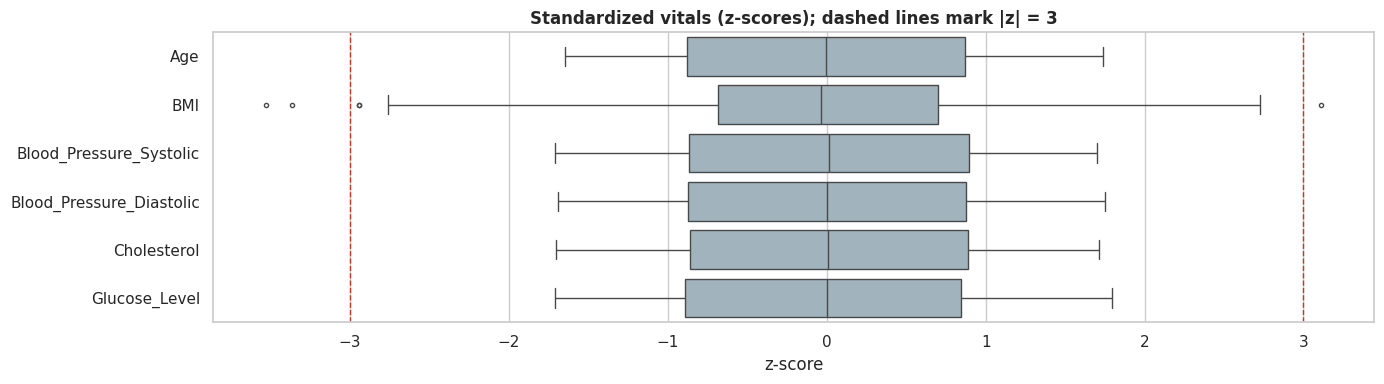


Patients with implausible BMI (<15 or >60): 10


,Age,BMI,Blood_Pressure_Systolic,Blood_Pressure_Diastolic,Cholesterol,Glucose_Level,Heart_Disease,Diabetes,Stroke
3,38,9.6,162,102,274,87,0,0,0
558,38,10.4,133,117,229,103,0,0,0
1631,19,12.5,173,104,163,79,0,0,0
1990,40,12.5,91,106,204,145,0,0,0
1450,51,13.4,143,78,211,87,0,0,0
306,80,13.6,100,84,208,106,0,0,0
827,25,13.7,128,90,299,135,0,0,0
1268,29,13.9,129,93,272,142,0,0,0
25,64,14.2,127,67,150,145,0,0,0
1199,42,14.5,169,92,227,94,0,0,0


In [11]:
PLAUSIBLE = {  # realistic adult ranges
    "Age": (18, 100),
    "BMI": (15, 60),
    "Blood_Pressure_Systolic": (80, 220),
    "Blood_Pressure_Diastolic": (40, 130),
    "Cholesterol": (100, 400),
    "Glucose_Level": (50, 400),
}

rows = []
for col in VITALS:
    q1, q3 = eda_df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_iqr = ((eda_df[col] < lo) | (eda_df[col] > hi)).sum()
    plo, phi = PLAUSIBLE[col]
    n_implaus = ((eda_df[col] < plo) | (eda_df[col] > phi)).sum()
    rows.append({"feature": col, "min": eda_df[col].min(), "max": eda_df[col].max(),
                 "IQR_lower": round(lo, 1), "IQR_upper": round(hi, 1),
                 "IQR_outliers": n_iqr, "implausible_values": n_implaus})
outlier_report = pd.DataFrame(rows).set_index("feature")
display(outlier_report)

# Diastolic should always be lower than systolic
bp_inverted = (eda_df["Blood_Pressure_Diastolic"] >= eda_df["Blood_Pressure_Systolic"]).sum()
print(f"Rows where diastolic >= systolic (physiologically suspicious): {bp_inverted} "
      f"({bp_inverted/len(eda_df):.1%} of training rows)")

plt.figure(figsize=(14, 4))
z = (eda_df[VITALS] - eda_df[VITALS].mean()) / eda_df[VITALS].std()
sns.boxplot(data=z, orient="h", color="#9db4c0", fliersize=3)
plt.axvline(-3, color="#c0392b", ls="--", lw=1); plt.axvline(3, color="#c0392b", ls="--", lw=1)
plt.title("Standardized vitals (z-scores); dashed lines mark |z| = 3", fontweight="bold")
plt.xlabel("z-score")
plt.tight_layout()
plt.show()

flagged = eda_df[(eda_df["BMI"] < PLAUSIBLE["BMI"][0]) | (eda_df["BMI"] > PLAUSIBLE["BMI"][1])]
print(f"\nPatients with implausible BMI (<15 or >60): {len(flagged)}")
display(flagged[VITALS + TARGETS].sort_values("BMI").head(10))

2.9 Risk-pattern check (threshold combinations)

The box plots suggest each outcome is driven by a few vitals together. This cell tests simple threshold combinations to see how cleanly they separate the classes. If a rule captures almost every positive case, the dataset is likely synthetic and generated from that rule, which means models will score very high and the team should say so in the report.

In [12]:
rules = {
    "Stroke":        (eda_df["Age"] > 60) & (eda_df["Blood_Pressure_Systolic"] > 150) & (eda_df["Smoking"] == 1),
    "Heart_Disease": (eda_df["Age"] > 50) & (eda_df["Blood_Pressure_Systolic"] > 140) & (eda_df["Cholesterol"] > 240),
    "Diabetes":      (eda_df["BMI"] > 30) & (eda_df["Glucose_Level"] > 140),
}
labels = {
    "Stroke":        "Age > 60 AND Systolic > 150 AND Smoker",
    "Heart_Disease": "Age > 50 AND Systolic > 140 AND Cholesterol > 240",
    "Diabetes":      "BMI > 30 AND Glucose > 140",
}
rule_rows = []
for t, cond in rules.items():
    pos = eda_df[t] == 1
    rule_rows.append({
        "target": t, "rule": labels[t],
        "patients_matching_rule": int(cond.sum()),
        "rate_if_rule_true_%": round(eda_df.loc[cond, t].mean() * 100, 1),
        "rate_if_rule_false_%": round(eda_df.loc[~cond, t].mean() * 100, 1),
        "share_of_positives_captured_%": round((cond & pos).sum() / pos.sum() * 100, 1),
    })
display(pd.DataFrame(rule_rows).set_index("target"))

,rule,patients_matching_rule,rate_if_rule_true_%,rate_if_rule_false_%,share_of_positives_captured_%
target,,,,,
Stroke,Age > 60 AND Systolic > 150 AND Smoker,71,100.0,0.0,100.0
Heart_Disease,Age > 50 AND Systolic > 140 AND Cholesterol > 240,109,100.0,0.0,100.0
Diabetes,BMI > 30 AND Glucose > 140,174,100.0,0.0,100.0


2.10 Key findings and handoff

All numbers below come from the training set (n = 1,400) outputs above.

Overall data quality

No missing values. Gender, Smoking, Alcohol_Intake, Physical_Activity and Family_History are all close to a 50/50 split.
Feature-to-feature correlations are all very weak (highest |r| = 0.05), so there is no multicollinearity to worry about.
For Member 3 (Encoding & Scaling: Great)

Gender is the only text column. Every lifestyle factor and target is already 0/1, so only Gender needs get_dummies(drop_first=True).
All six numeric vitals have skewness between −0.02 and +0.05 (see 2.3), so StandardScaler alone is enough. No log or power transform is needed.
BMI has 10 clinically implausible values below 15 (minimum 9.6), and 5 of them are also IQR outliers. None of these 10 patients has any of the three diseases. We recommend capping BMI at 15 (with the cap set from the training set) before scaling, so these values don't stretch BMI's scale. No other vital has outliers.
For Member 4 (Feature Engineering & Balancing: Quan)

Class imbalance in the training set:
Stroke: 71 positive (5.1%), about 1 : 19
Heart_Disease: 109 positive (7.8%), about 1 : 12
Diabetes: 174 positive (12.4%), about 1 : 7
Stroke is the most imbalanced target, so SMOTE or class_weight="balanced" should be applied to the training set only.
Stroke risk depends heavily on age. The stroke rate is 0% for every age band up to 60, then 14.2% for ages 61–70 and 14.8% for 71+.
124 rows (8.9%) have diastolic ≥ systolic, which is not physiologically realistic. A Pulse Pressure feature (systolic − diastolic) would be negative for these rows, so it should be clipped at 0 or the rows flagged.
Strongest signals by target, using correlation with each target:
Stroke: Age (+0.26), Systolic BP (+0.26), Smoking (+0.23)
Heart_Disease: Cholesterol (+0.31), Systolic BP (+0.27), Age (+0.26)
Diabetes: BMI (+0.47), Glucose (+0.37)
Suggested engineered features:
Age 60+ flag
BP Risk Category (systolic > 140 and > 150)
High Cholesterol flag (> 240)
Obese flag (BMI > 30)
High Glucose flag (> 140)
Important dataset limitation (for the whole team and the report) Each outcome is fully determined by a simple threshold rule (see 2.9):

Stroke = Age > 60 AND Systolic > 150 AND Smoker
Heart_Disease = Age > 50 AND Systolic > 140 AND Cholesterol > 240
Diabetes = BMI > 30 AND Glucose > 140
Each rule captures 100% of positive cases with 0 false positives in the training set. The dataset was therefore generated synthetically from these rules. Tree-based models will likely reach near-perfect scores, and this reflects how the data was built, not real-world predictive power. The report should state this as a limitation.